# Clase 2 · Parte 1 — Para dónde va el agua: DEM, altura sobre el cauce (HAND), H3 y K-means

**Seminario CyT · Maestría en Minería de Datos · UTN FRP**

La pregunta de la cursada sigue siendo la misma:

> Con las variables de esta semana, ¿qué áreas se agrupan entre sí? Cuando el río sube, ¿qué se lee de esos grupos?

Esta semana las variables salen del **terreno** (un DEM). La idea de hidrología es una sola, y es de sentido común:

> **El agua baja.** Sigue la pendiente hasta juntarse en un cauce. Un lugar se moja primero si está **bajo respecto del cauce al que drena**, no si está "cerca del río".

Por eso **no** usamos una franja (buffer) alrededor del río. Usamos la **altura sobre el cauce más cercano en el sentido del flujo** (HAND, *Height Above Nearest Drainage*).

**Qué hacemos en este notebook**

1. Bajamos un pedazo del DEM Copernicus GLO-30 (gratis, sin cuenta).
2. Perfil transversal: del cauce a la barranca, con marcas a +2, +4 y +6 m.
3. Dirección de flujo y acumulación (para dónde va el agua y cuánta área le aporta a cada píxel).
4. Red de cauces y perfil longitudinal de un cauce.
5. HAND y los tres escenarios +2 / +4 / +6 m.
6. Grilla H3 y una tabla por hexágono.
7. K-means escalado e interpretación: el grupo de riesgo es **"bajo Y drena al cauce"**.

**Lo que esto NO es:** no es un modelo hidráulico, no es un pronóstico y no dice que un lugar *se va a* inundar. Los +2/+4/+6 m son escenarios para leer el terreno.

Los ejercicios tienen la solución en una celda colapsada (*Solución*). Intentalo antes de abrirla.

## 0. Instalación y parámetros
En Colab corré esta celda una vez. Instala solo lo que falta.

In [25]:
import importlib, subprocess, sys
faltan = [p for p, m in [("pysheds","pysheds"),("h3","h3"),("rasterio","rasterio"),("geopandas","geopandas"),
                         ("rasterstats","rasterstats"),("scikit-learn","sklearn"),("pyarrow","pyarrow")]
          if importlib.util.find_spec(m) is None]
if faltan:
    print("Instalando:", faltan)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
else:
    print("Todo instalado.")

Todo instalado.


In [26]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Polygon, LineString, box
import h3
from scipy import ndimage
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
warnings.filterwarnings("ignore")

# pysheds 0.5 todavía llama a np.in1d, que NumPy >= 2.4 eliminó. Parche mínimo:
if not hasattr(np, "in1d"):
    np.in1d = np.isin
from pysheds.grid import Grid
from pysheds.sview import Raster, ViewFinder
print("numpy", np.__version__, "| h3", h3.__version__)

numpy 2.1.3 | h3 4.5.0


In [27]:
# ---------------- PARÁMETROS (cambiá acá, no en el resto del notebook) ----------------
# Ventana de cursada: tramo Paraná – Santa Fe (la misma de la clase 1). [oeste, sur, este, norte]
BBOX = (-60.85, -31.95, -60.35, -31.45)
CRS_METRICO = "EPSG:32720"      # UTM 20S: metros, para pendiente, distancias y áreas
RES_M = 30                      # resolución del DEM reproyectado (m)

DEM_FUENTE = "copernicus30"     # "copernicus30" | "copernicus90" | "local"
DEM_LOCAL = None                # ruta a un GeoTIFF propio (p. ej. MDE-Ar del IGN convertido a .tif)

UMBRAL_CAUCE_KM2 = 2.0          # área de aporte mínima para llamar "cauce" a un píxel
ESCENARIOS_M = [2, 4, 6]        # alturas sobre el cauce
H3_RES = 8                      # ~0,7 km² por hexágono
K = 4                           # grupos de K-means
SEMILLA = 42

# Perfil transversal (lon, lat): arranca en el agua y sube a la barranca de Paraná
PERFIL_A = (-60.545, -31.700)
PERFIL_B = (-60.515, -31.740)
# Punto cerca de un cauce para el perfil longitudinal (se "engancha" al cauce más cercano)
PUNTO_CAUCE = (-60.47, -31.78)

# Google Drive: cada notebook corre en una sesión de Colab distinta, así que TODO lo que se
# comparte entre notebooks vive en esta carpeta de Drive (no en el disco local de la sesión).
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/datos_clase2_publico"   # misma ruta en 01, 02, 03 y 04
os.makedirs(DRIVE_DIR, exist_ok=True)
DATA_DIR = DRIVE_DIR

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. El DEM

Usamos **Copernicus DEM GLO-30** (30 m). Está publicado como *Cloud Optimized GeoTIFF* en AWS, en tiles de 1°×1°, y se puede leer **solo la ventana** que nos interesa, sin bajar el archivo entero.

Ojo: Copernicus es un **modelo de superficie** (DSM). Incluye edificios y árboles. En la ciudad eso mete ruido en la pendiente y en la HAND. Alternativa nacional: el **MDE-Ar v2.1 del IGN** (30 m, se baja a mano desde el sitio del IGN en formato `.img`; ver README). Para usarlo, convertilo a GeoTIFF, poné `DEM_FUENTE = "local"` y la ruta en `DEM_LOCAL`.

La función de abajo:
- calcula qué tiles cubren el BBOX,
- intenta leer cada tile por HTTP (`/vsicurl/`) con reintentos,
- si GLO-30 falla, prueba GLO-90,
- arma un mosaico, reproyecta a UTM y lo guarda en `DATA_DIR`. Si el archivo ya existe, no baja nada.

In [28]:
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")

def _tile_cop(lat_sw, lon_sw, res="30"):
    ns = "N" if lat_sw >= 0 else "S"; ew = "E" if lon_sw >= 0 else "W"
    code_ = "10" if res == "30" else "30"
    name = f"Copernicus_DSM_COG_{code_}_{ns}{abs(lat_sw):02d}_00_{ew}{abs(lon_sw):03d}_00_DEM"
    return f"https://copernicus-dem-{res}m.s3.eu-central-1.amazonaws.com/{name}/{name}.tif"

def _leer_ventana(url, bbox, reintentos=3):
    for i in range(reintentos):
        try:
            with rasterio.open("/vsicurl/" + url) as s:
                b = s.bounds
                inter = (max(bbox[0], b.left), max(bbox[1], b.bottom), min(bbox[2], b.right), min(bbox[3], b.top))
                w = from_bounds(*inter, s.transform).round_offsets().round_lengths()
                return s.read(1, window=w), s.window_transform(w), s.crs
        except Exception as e:
            print(f"  intento {i+1} falló: {e}"); time.sleep(3 * (i + 1))
    return None

def bajar_dem(bbox, fuente=DEM_FUENTE, local=DEM_LOCAL):
    salida = os.path.join(DATA_DIR, "dem_utm.tif")
    if os.path.exists(salida):
        print("Ya existe", salida); return salida
    if fuente == "local":
        with rasterio.open(local) as s:
            w = from_bounds(*bbox, s.transform); arr = s.read(1, window=w).astype("float32")
            tr, crs = s.window_transform(w), s.crs
            if s.nodata is not None: arr[arr == s.nodata] = np.nan
        partes = [(arr, tr, crs)]
    else:
        orden = ["30", "90"] if fuente == "copernicus30" else ["90"]
        partes = []
        for res in orden:
            partes = []
            for lat in range(math.floor(bbox[1]), math.ceil(bbox[3])):
                for lon in range(math.floor(bbox[0]), math.ceil(bbox[2])):
                    url = _tile_cop(lat, lon, res); print("Leyendo", url)
                    r = _leer_ventana(url, bbox)
                    if r is None: partes = None; break
                    partes.append(r)
                if partes is None: break
            if partes: print(f"OK con GLO-{res}"); break
        if not partes:
            raise RuntimeError("No se pudo bajar el DEM. Probá más tarde o usá DEM_FUENTE='local'.")
    # Reproyectar cada parte al mismo grid UTM y combinar
    T, W, H = calculate_default_transform("EPSG:4326", CRS_METRICO, 1000, 1000, *bbox, resolution=RES_M)
    out = np.full((H, W), np.nan, "float32")
    for arr, tr, crs in partes:
        tmp = np.full((H, W), np.nan, "float32")
        reproject(arr.astype("float32"), tmp, src_transform=tr, src_crs=crs, dst_transform=T,
                  dst_crs=CRS_METRICO, resampling=Resampling.bilinear, src_nodata=np.nan, dst_nodata=np.nan)
        out = np.where(np.isnan(out), tmp, out)
    out[np.isnan(out)] = -9999
    prof = dict(driver="GTiff", height=H, width=W, count=1, dtype="float32", crs=CRS_METRICO,
                transform=T, nodata=-9999, compress="deflate")
    with rasterio.open(salida, "w", **prof) as d: d.write(out, 1)
    print("Guardado", salida, out.shape); return salida

t0 = time.time()
DEM_PATH = bajar_dem(BBOX)
print(f"{time.time()-t0:.1f} s")

Ya existe /content/drive/MyDrive/datos_clase2_publico/dem_utm.tif
0.0 s


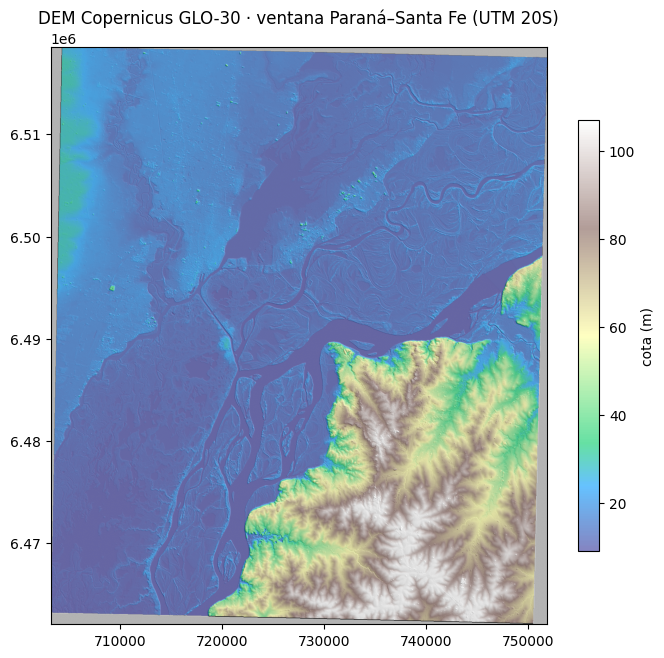

cota mín / mediana / máx: -2.3 15.3 132.6


In [29]:
with rasterio.open(DEM_PATH) as s:
    dem = s.read(1).astype("float64"); TRANSF = s.transform; NODATA = s.nodata
dem[dem == NODATA] = np.nan
VALIDO = ~np.isnan(dem)
CELDA_KM2 = (RES_M * RES_M) / 1e6
EXT = (TRANSF.c, TRANSF.c + TRANSF.a * dem.shape[1], TRANSF.f + TRANSF.e * dem.shape[0], TRANSF.f)

# sombreado simple para que el relieve se vea
gy, gx = np.gradient(np.nan_to_num(dem, nan=np.nanmedian(dem)), RES_M)
sombra = np.clip(0.7 - (gx - gy) * 2, 0, 1)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(sombra, cmap="gray", extent=EXT)
im = ax.imshow(dem, cmap="terrain", alpha=0.6, extent=EXT, vmin=np.nanpercentile(dem, 1), vmax=np.nanpercentile(dem, 99))
plt.colorbar(im, ax=ax, shrink=0.7, label="cota (m)")
ax.set_title("DEM Copernicus GLO-30 · ventana Paraná–Santa Fe (UTM 20S)")
plt.show()
print("cota mín / mediana / máx:", np.nanmin(dem).round(1), np.nanmedian(dem).round(1), np.nanmax(dem).round(1))

## 2. Perfil transversal: del cauce a la barranca

Trazamos una línea desde el agua hasta la barranca de Paraná y leemos la cota cada 30 m. Las líneas horizontales marcan +2, +4 y +6 m sobre la cota del punto de partida (el agua).

Leelo en voz alta: ¿hasta dónde sigue bajo el terreno? ¿Dónde "pega" contra la barranca? Si el agua sube 6 m, ¿hasta qué distancia llega en *este* corte?

+2 m: el terreno queda por debajo hasta ~2250 m del arranque (primer cruce: 450 m)
+4 m: el terreno queda por debajo hasta ~2280 m del arranque (primer cruce: 510 m)
+6 m: el terreno queda por debajo hasta ~2340 m del arranque (primer cruce: 2370 m)


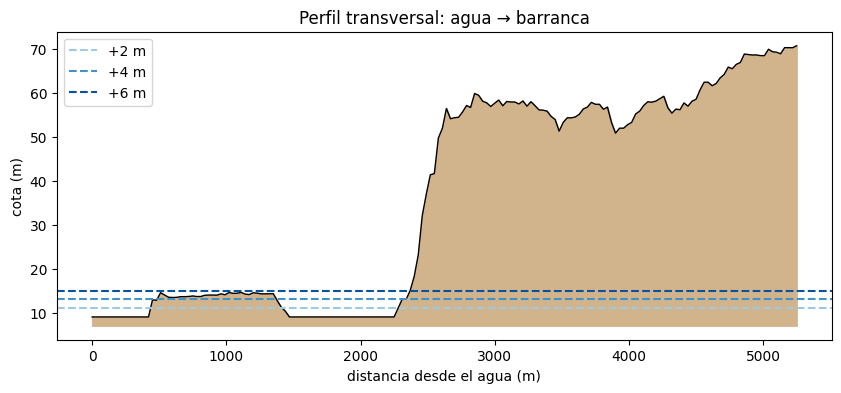

In [30]:
from pyproj import Transformer
A_UTM = Transformer.from_crs("EPSG:4326", CRS_METRICO, always_xy=True)
UTM_A_GEO = Transformer.from_crs(CRS_METRICO, "EPSG:4326", always_xy=True)

def muestrear(arr, xs, ys):
    cols = ((np.asarray(xs) - TRANSF.c) / TRANSF.a).astype(int)
    rows = ((np.asarray(ys) - TRANSF.f) / TRANSF.e).astype(int)
    ok = (rows >= 0) & (rows < arr.shape[0]) & (cols >= 0) & (cols < arr.shape[1])
    v = np.full(len(cols), np.nan); v[ok] = arr[rows[ok], cols[ok]]
    return v

def perfil(arr, a_lonlat, b_lonlat, paso=RES_M):
    xa, ya = A_UTM.transform(*a_lonlat); xb, yb = A_UTM.transform(*b_lonlat)
    L = math.hypot(xb - xa, yb - ya); d = np.arange(0, L, paso)
    xs = xa + (xb - xa) * d / L; ys = ya + (yb - ya) * d / L
    return d, muestrear(arr, xs, ys)

d, z = perfil(dem, PERFIL_A, PERFIL_B)
z0 = z[0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(d, z, np.nanmin(z) - 2, color="tan"); ax.plot(d, z, "k", lw=1)
for h, c in zip(ESCENARIOS_M, ["#9ecae1", "#4292c6", "#08519c"]):
    ax.axhline(z0 + h, color=c, ls="--", label=f"+{h} m")
    adentro = d[z <= z0 + h]
    print(f"+{h} m: el terreno queda por debajo hasta ~{adentro.max():.0f} m del arranque (primer cruce: "
          f"{d[np.argmax(z > z0 + h)]:.0f} m)")
ax.set_xlabel("distancia desde el agua (m)"); ax.set_ylabel("cota (m)"); ax.legend()
ax.set_title("Perfil transversal: agua → barranca"); plt.show()

## 3. Para dónde va el agua: dirección de flujo y acumulación

1. **Rellenar pozos.** Un DEM tiene pocitos falsos (ruido) donde el agua "quedaría atrapada". Los rellenamos para que siempre haya salida.
2. **Dirección de flujo (D8).** Cada píxel le pasa su agua al vecino más bajo de sus 8 vecinos.
3. **Acumulación.** Para cada píxel contamos cuántos píxeles le mandan agua aguas arriba. Multiplicado por el área del píxel, es el **área de aporte** (km²). Mucha acumulación = por ahí pasa un cauce.

Usamos `pysheds`. En esta ventana tarda segundos.

listo en 14.1 s · área de aporte máx. dentro de la ventana: 510 km²


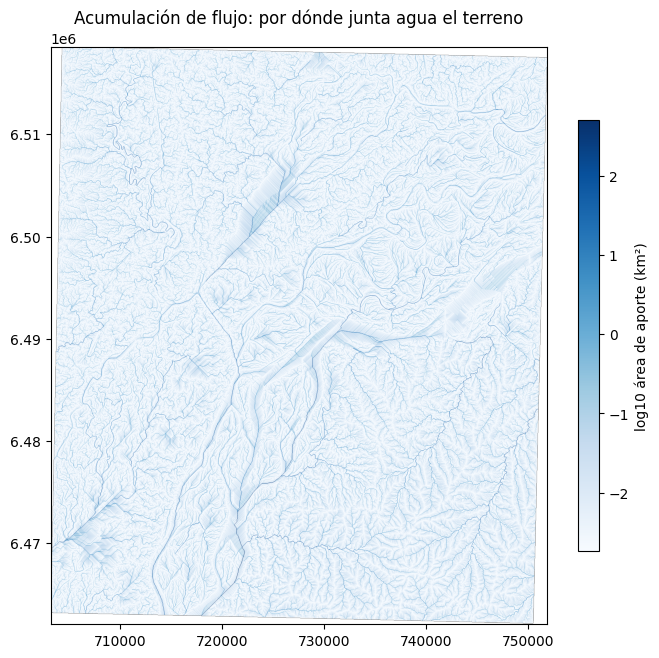

In [31]:
t0 = time.time()
grid = Grid.from_raster(DEM_PATH)
dem_ps = grid.read_raster(DEM_PATH)
dem_relleno = grid.resolve_flats(grid.fill_depressions(grid.fill_pits(dem_ps)))
fdir = grid.flowdir(dem_relleno)
acc = np.asarray(grid.accumulation(fdir), dtype="float64")
acc[~VALIDO] = np.nan
area_aporte_km2 = acc * CELDA_KM2
print(f"listo en {time.time()-t0:.1f} s · área de aporte máx. dentro de la ventana: {np.nanmax(area_aporte_km2):.0f} km²")

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(np.log10(area_aporte_km2 + CELDA_KM2), cmap="Blues", extent=EXT)
plt.colorbar(im, ax=ax, shrink=0.7, label="log10 área de aporte (km²)")
ax.set_title("Acumulación de flujo: por dónde junta agua el terreno"); plt.show()

## 4. La red de cauces

Un píxel es **cauce** si su área de aporte supera `UMBRAL_CAUCE_KM2`. El umbral es una decisión nuestra: más bajo = más arroyitos; más alto = solo los cauces grandes. Lo vamos a mover en el Ejercicio 1.

Detalle honesto: el río Paraná entra a la ventana desde afuera, así que su acumulación "real" es muchísimo mayor. Para HAND no importa: alcanza con que el río quede marcado como cauce.

píxeles de cauce: 42,752 (1.5 % de la ventana)


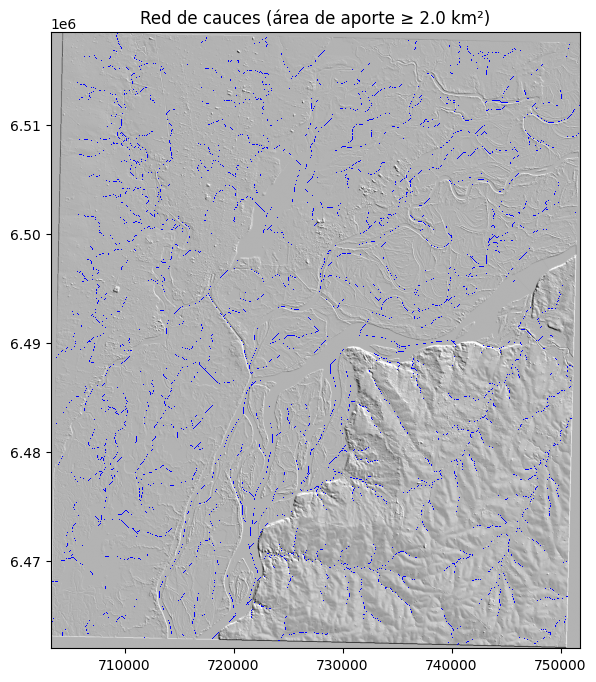

In [32]:
cauce = (area_aporte_km2 >= UMBRAL_CAUCE_KM2)
def como_raster(mascara):   # pysheds pide su propio tipo Raster, con la georreferencia del DEM
    vf = ViewFinder(affine=dem_ps.affine, shape=dem_ps.shape, crs=dem_ps.crs, nodata=False)
    return Raster(np.asarray(mascara, dtype=bool), viewfinder=vf)
print(f"píxeles de cauce: {cauce.sum():,} ({100*cauce.sum()/VALIDO.sum():.1f} % de la ventana)")
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(sombra, cmap="gray", extent=EXT)
ax.imshow(np.where(cauce, 1, np.nan), cmap="winter", extent=EXT, interpolation="nearest")
ax.set_title(f"Red de cauces (área de aporte ≥ {UMBRAL_CAUCE_KM2} km²)"); plt.show()

### 4.1 Perfil longitudinal de un cauce

Nos enganchamos al cauce más cercano a `PUNTO_CAUCE` y seguimos la dirección de flujo aguas abajo, píxel a píxel, hasta salir de la ventana. Si el DEM está bien, la cota **baja** (con algo de ruido). Eso es "el agua sigue la pendiente", dibujado.

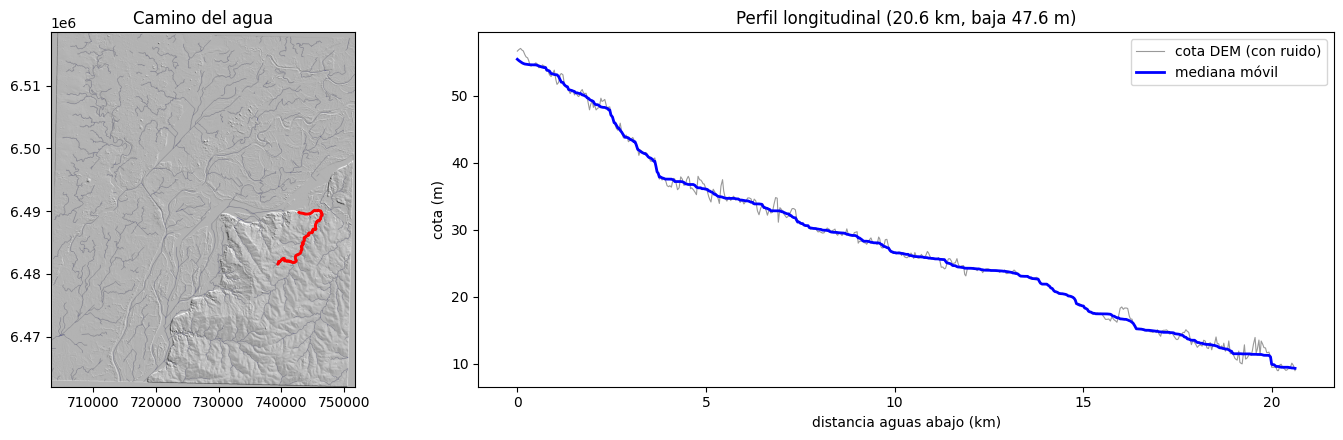

In [33]:
DIRMAP = (64, 128, 1, 2, 4, 8, 16, 32)   # N, NE, E, SE, S, SW, W, NW (convención por defecto de pysheds)
PASOS = {64: (-1, 0), 128: (-1, 1), 1: (0, 1), 2: (1, 1), 4: (1, 0), 8: (1, -1), 16: (0, -1), 32: (-1, -1)}
FD = np.asarray(fdir)

def enganchar_a_cauce(lonlat, radio_px=60):
    x, y = A_UTM.transform(*lonlat)
    r0, c0 = int((y - TRANSF.f) / TRANSF.e), int((x - TRANSF.c) / TRANSF.a)
    r1, r2 = max(r0 - radio_px, 0), min(r0 + radio_px, cauce.shape[0])
    c1, c2 = max(c0 - radio_px, 0), min(c0 + radio_px, cauce.shape[1])
    rr, cc = np.nonzero(cauce[r1:r2, c1:c2])
    if len(rr) == 0: raise ValueError("No hay cauce cerca: mové PUNTO_CAUCE o bajá el umbral.")
    i = np.argmin((rr + r1 - r0) ** 2 + (cc + c1 - c0) ** 2)
    return rr[i] + r1, cc[i] + c1

def seguir_flujo(r, c, max_pasos=20000):
    camino = [(r, c)]
    for _ in range(max_pasos):
        paso = PASOS.get(int(FD[r, c]))
        if paso is None: break
        r, c = r + paso[0], c + paso[1]
        if not (0 <= r < FD.shape[0] and 0 <= c < FD.shape[1]) or not VALIDO[r, c]: break
        camino.append((r, c))
    return np.array(camino)

cam = seguir_flujo(*enganchar_a_cauce(PUNTO_CAUCE))
paso_m = np.where((np.diff(cam, axis=0) != 0).all(axis=1), RES_M * 2 ** 0.5, RES_M)
dist = np.concatenate([[0], np.cumsum(paso_m)]) / 1000
z_cam = dem[cam[:, 0], cam[:, 1]]

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
axs[0].imshow(sombra, cmap="gray", extent=EXT); axs[0].imshow(np.where(cauce, 1, np.nan), cmap="winter", extent=EXT)
xs = TRANSF.c + (cam[:, 1] + 0.5) * TRANSF.a; ys = TRANSF.f + (cam[:, 0] + 0.5) * TRANSF.e
axs[0].plot(xs, ys, "r", lw=2); axs[0].set_title("Camino del agua")
axs[1].plot(dist, z_cam, color="0.6", lw=0.8, label="cota DEM (con ruido)")
axs[1].plot(dist, pd.Series(z_cam).rolling(31, center=True, min_periods=1).median(), "b", lw=2, label="mediana móvil")
axs[1].set_xlabel("distancia aguas abajo (km)"); axs[1].set_ylabel("cota (m)"); axs[1].legend()
axs[1].set_title(f"Perfil longitudinal ({dist[-1]:.1f} km, baja {z_cam[0]-z_cam[-1]:.1f} m)")
plt.tight_layout(); plt.show()

## 5. HAND: altura sobre el cauce al que drena cada píxel

Para cada píxel: seguimos su camino de flujo hasta que toca un píxel de cauce, y restamos.

**HAND = cota del píxel − cota del cauce donde desemboca su agua.**

- HAND ≈ 0: el píxel está prácticamente al nivel de su cauce (se moja primero).
- HAND alto: está arriba de su cauce (barranca, loma), aunque esté a 200 m del río.

**Lo que HAND no sabe:** defensas y terraplenes (las ciudades del tramo tienen obras de defensa que un DEM de 30 m no ve bien), bombas, desagües pluviales, edificios (el DSM los cuenta como terreno). Es el terreno solo.

Los escenarios son simples: un píxel queda "adentro" de +2 m si su HAND < 2 m, y así con 4 y 6. No es un nivel de río pronosticado; es una regla para leer el terreno.

HAND en 0.9 s · percentiles 10/50/90: [ 0.   1.8 18.5]
HAND < 2 m: 46.5 % de la ventana · 1,278 km²
HAND < 4 m: 59.0 % de la ventana · 1,621 km²
HAND < 6 m: 65.1 % de la ventana · 1,789 km²


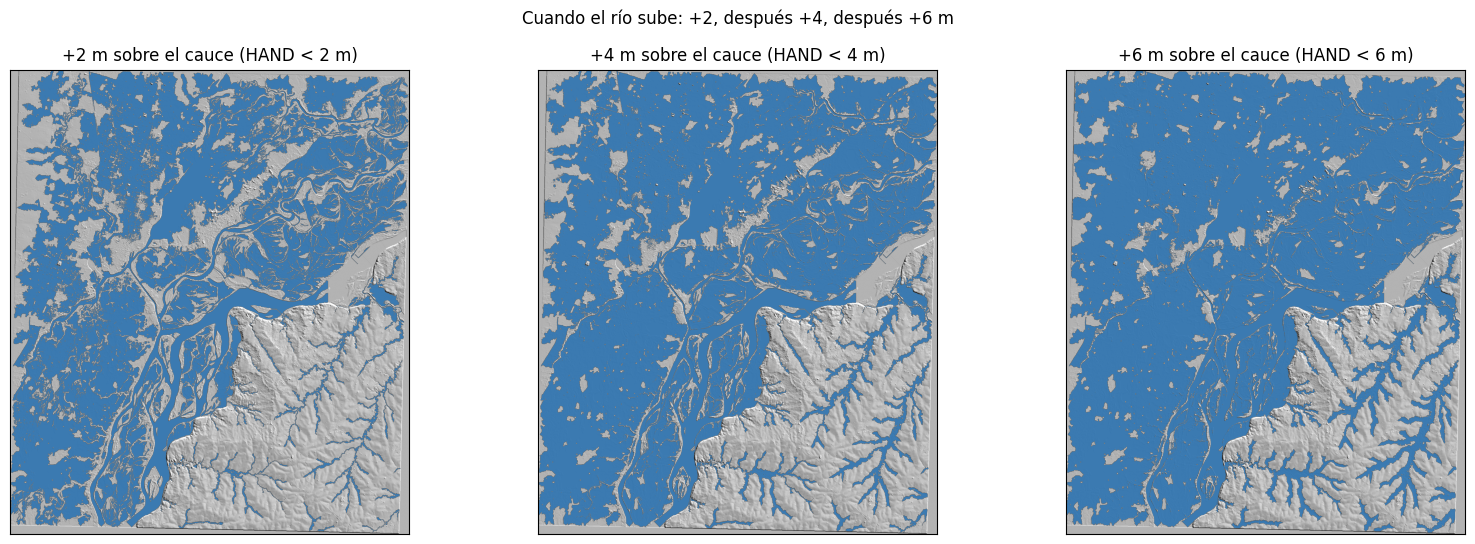

In [34]:
t0 = time.time()
hand = np.asarray(grid.compute_hand(fdir, dem_ps, como_raster(cauce)), dtype="float64")
hand[~VALIDO] = np.nan
hand = np.clip(hand, 0, None)   # pequeños negativos = ruido del relleno
print(f"HAND en {time.time()-t0:.1f} s · percentiles 10/50/90:", np.nanpercentile(hand, [10, 50, 90]).round(1))
for h in ESCENARIOS_M:
    print(f"HAND < {h} m: {100*np.nanmean(hand < h):.1f} % de la ventana · {np.nansum(hand < h)*CELDA_KM2:,.0f} km²")

fig, axs = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, h in zip(axs, ESCENARIOS_M):
    ax.imshow(sombra, cmap="gray", extent=EXT)
    ax.imshow(np.where(hand < h, 1, np.nan), cmap="Blues", vmin=0, vmax=1.3, extent=EXT, alpha=0.8)
    ax.set_title(f"+{h} m sobre el cauce (HAND < {h} m)"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Cuando el río sube: +2, después +4, después +6 m"); plt.tight_layout(); plt.show()

In [35]:
# Guardamos los rasters para la Parte 2 (cruces)
prof = dict(driver="GTiff", height=dem.shape[0], width=dem.shape[1], count=1, dtype="float32",
            crs=CRS_METRICO, transform=TRANSF, nodata=-9999, compress="deflate")
for nombre, arr in {"hand": hand, "area_aporte_km2": area_aporte_km2, "cauce": cauce.astype(float)}.items():
    a = np.where(VALIDO, arr, -9999).astype("float32")
    with rasterio.open(os.path.join(DATA_DIR, f"{nombre}_utm.tif"), "w", **prof) as d: d.write(a, 1)
print(sorted(os.listdir(DATA_DIR)))

['area_aporte_km2_utm.tif', 'cauce_utm.tif', 'centroides_kmeans.csv', 'dem_utm.tif', 'hand_utm.tif', 'hexes_terreno.parquet']


### 5.1 ¿Por qué no una franja de 500 m?

En la clase 1 armamos una franja de 500 m alrededor del cauce. Comparemos con HAND, píxel a píxel:

- píxeles **dentro** de la franja pero con HAND > 6 m (la franja los marca y el agua no llega: barranca),
- píxeles **fuera** de la franja con HAND < 2 m (la franja no los ve y son de lo más bajo: bañados, arroyos interiores).

In [36]:
dist_cauce_m = ndimage.distance_transform_edt(~cauce) * RES_M
franja = (dist_cauce_m <= 500) & VALIDO
f_alto = np.nansum(franja & (hand > 6)) * CELDA_KM2
f_bajo_fuera = np.nansum(~franja & VALIDO & (hand < 2)) * CELDA_KM2
print(f"Franja 500 m: {franja.sum()*CELDA_KM2:,.0f} km²")
print(f"  dentro de la franja pero con HAND > 6 m: {f_alto:,.1f} km² ({100*f_alto/(franja.sum()*CELDA_KM2):.1f} % de la franja)")
print(f"  fuera de la franja y con HAND < 2 m:     {f_bajo_fuera:,.1f} km²")

Franja 500 m: 1,317 km²
  dentro de la franja pero con HAND > 6 m: 192.1 km² (14.6 % de la franja)
  fuera de la franja y con HAND < 2 m:     468.4 km²


## 6. Grilla H3 y tabla por hexágono

Pasamos de píxeles a hexágonos H3 (resolución 8). Cada píxel cae en un hexágono; agrupamos y resumimos:

| columna | qué es |
|---|---|
| `cota_media` | cota media del DEM (m) |
| `pendiente_media` | pendiente media (m/m) |
| `aporte_log_max` | log10 del área de aporte máxima en el hex (km²): ¿pasa un cauce por acá? |
| `hand_mediana` | HAND mediana (m) |
| `frac_hand_lt2/4/6` | fracción del hex con HAND < 2, 4, 6 m |

Es un *groupby*: lo mismo que harían con un DataFrame cualquiera, con el índice H3 como clave.

In [37]:
t0 = time.time()
gy, gx = np.gradient(np.where(VALIDO, dem, np.nan), RES_M)
pendiente = np.hypot(gx, gy)          # m/m

filas, cols = np.nonzero(VALIDO)
xs = TRANSF.c + (cols + 0.5) * TRANSF.a; ys = TRANSF.f + (filas + 0.5) * TRANSF.e
lon, lat = UTM_A_GEO.transform(xs, ys)
celdas = [h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(lat, lon)]
px = pd.DataFrame({
    "h3": celdas,
    "cota": dem[filas, cols],
    "pendiente": pendiente[filas, cols],
    "aporte_log": np.log10(area_aporte_km2[filas, cols] + CELDA_KM2),
    "hand": hand[filas, cols],
})
for h in ESCENARIOS_M:
    px[f"hand_lt{h}"] = px["hand"] < h
tabla = px.groupby("h3").agg(
    n_pix=("cota", "size"), cota_media=("cota", "mean"), pendiente_media=("pendiente", "mean"),
    aporte_log_max=("aporte_log", "max"), hand_mediana=("hand", "median"),
    **{f"frac_hand_lt{h}": (f"hand_lt{h}", "mean") for h in ESCENARIOS_M})
# descartamos hexágonos cortados por el borde de la ventana (menos de la mitad de píxeles)
tabla = tabla[tabla.n_pix >= 0.5 * tabla.n_pix.median()].reset_index()

def hex_poly(c):
    return Polygon([(lo, la) for la, lo in h3.cell_to_boundary(c)])
hexes = gpd.GeoDataFrame(tabla, geometry=[hex_poly(c) for c in tabla.h3], crs="EPSG:4326")
# Algunos hex del borde no tienen HAND: su agua sale de la ventana sin tocar un cauce. Los sacamos y lo decimos.
sin_hand = hexes.hand_mediana.isna().sum()
hexes = hexes.dropna(subset=["hand_mediana"]).reset_index(drop=True)
print(f"{len(hexes):,} hexágonos en {time.time()-t0:.1f} s · descartados por no tener HAND (borde): {sin_hand}")
hexes.drop(columns="geometry").describe().round(2)

4,562 hexágonos en 9.9 s · descartados por no tener HAND (borde): 82


,n_pix,cota_media,pendiente_media,aporte_log_max,hand_mediana,frac_hand_lt2,frac_hand_lt4,frac_hand_lt6
count,4562.00,4562.00,4562.00,4562.00,4562.00,4562.00,4562.00,4562.00
mean,625.72,28.57,0.02,0.30,5.21,0.49,0.63,0.69
std,27.67,26.75,0.01,0.76,8.04,0.37,0.38,0.37
min,316.00,8.50,0.00,-1.45,0.00,0.00,0.00,0.00
25%,627.00,12.42,0.01,-0.28,0.54,0.11,0.27,0.41
50%,629.00,15.00,0.02,0.20,1.62,0.53,0.79,0.90
75%,631.00,30.90,0.03,0.78,5.56,0.85,0.98,1.00
max,637.00,111.73,0.12,2.71,61.62,1.00,1.00,1.00


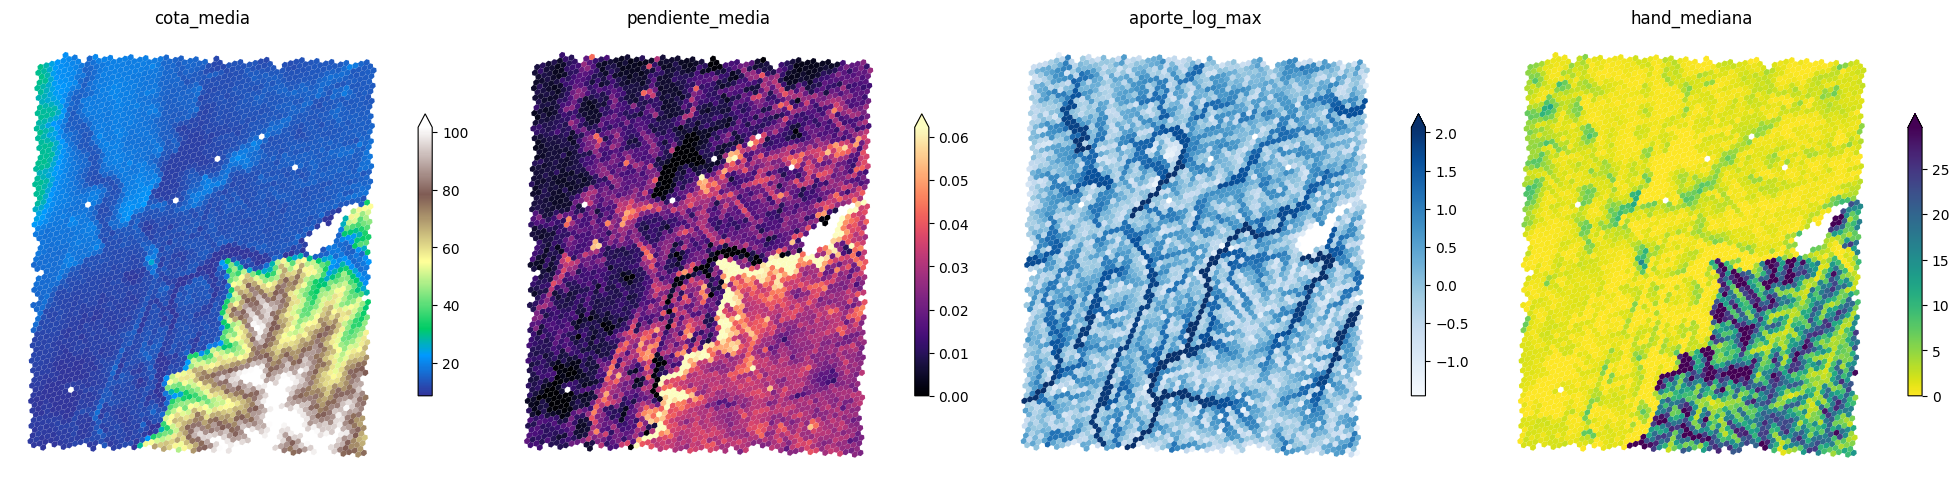

In [38]:
hexes_m = hexes.to_crs(CRS_METRICO)   # para dibujar sin deformar
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, col, cm in zip(axs, ["cota_media", "pendiente_media", "aporte_log_max", "hand_mediana"],
                       ["terrain", "magma", "Blues", "viridis_r"]):
    hexes_m.plot(column=col, cmap=cm, ax=ax, legend=True, legend_kwds={"shrink": 0.6},
               vmax=hexes[col].quantile(0.98)); ax.set_title(col); ax.set_axis_off()
plt.tight_layout(); plt.show()

## 7. K-means sobre los hexágonos

Variables: `cota_media`, `pendiente_media`, `aporte_log_max`, `hand_mediana`. Están en unidades muy distintas (metros, m/m, log km²), así que **escalamos** (`StandardScaler`) antes de K-means. Sin escalar, la cota mandaría sola.

Primero miramos inercia y silueta para k = 2..8. No hay un k "correcto": elegimos uno que se pueda leer en el mapa.

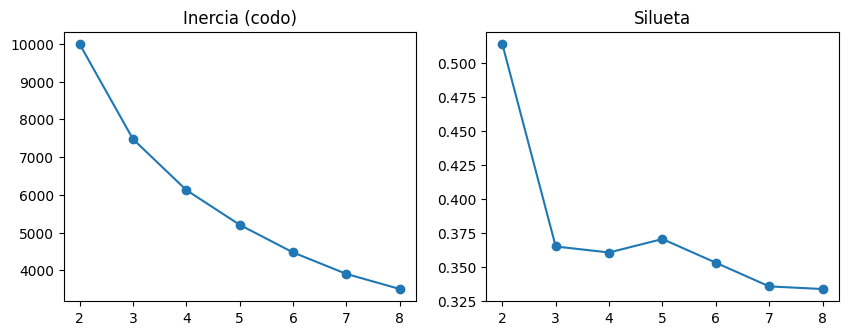

In [39]:
VARS = ["cota_media", "pendiente_media", "aporte_log_max", "hand_mediana"]
X = StandardScaler().fit_transform(hexes[VARS])
ks = range(2, 9); inercia, silu = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    inercia.append(km.inertia_); silu.append(silhouette_score(X, km.labels_, sample_size=min(3000, len(X)), random_state=SEMILLA))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(list(ks), inercia, "o-"); axs[0].set_title("Inercia (codo)")
axs[1].plot(list(ks), silu, "o-"); axs[1].set_title("Silueta"); plt.show()

km = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit(X)
hexes["grupo"] = km.labels_

## 8. Interpretar los grupos: el riesgo es "bajo **Y** drena al cauce"

Miramos los centroides **en unidades originales** (no escalados). La regla de lectura:

- **Grupo de riesgo:** HAND bajo **y** aporte alto. Está cerca del nivel de su cauce y además le llega agua.
- Un grupo con HAND alto no es de riesgo aunque esté pegado al río (barranca).
- Un grupo bajo pero con poco aporte (un bajo aislado) se moja por lluvia local, no por el río; lo dejamos aparte.

Para ordenar sin mirar el número del cluster calculamos un puntaje simple sobre los centroides escalados: `puntaje = aporte (z) − HAND (z)`. El grupo de puntaje más alto es el candidato a "bajo y drena". **El nombre final lo pone el mapa**, no el puntaje.

In [40]:
cent = hexes.groupby("grupo")[VARS].mean()
cent["n_hex"] = hexes.groupby("grupo").size()
z = (cent[VARS] - hexes[VARS].mean()) / hexes[VARS].std()
cent["puntaje_riesgo"] = (z["aporte_log_max"] - z["hand_mediana"]).round(2)

def describir(fila):
    t = lambda v, col: "bajo" if v < hexes[col].quantile(1/3) else ("alto" if v > hexes[col].quantile(2/3) else "medio")
    return f"HAND {t(fila.hand_mediana,'hand_mediana')} · aporte {t(fila.aporte_log_max,'aporte_log_max')} · pendiente {t(fila.pendiente_media,'pendiente_media')}"
cent["descripcion"] = cent.apply(describir, axis=1)
GRUPO_RIESGO = cent["puntaje_riesgo"].idxmax()
cent["rol"] = np.where(cent.index == GRUPO_RIESGO, "RIESGO: bajo y drena", "")
cent.sort_values("puntaje_riesgo", ascending=False).round(3)

,cota_media,pendiente_media,aporte_log_max,hand_mediana,n_hex,puntaje_riesgo,descripcion,rol
grupo,,,,,,,,
0,14.208,0.014,1.141,0.920,1298,1.65,HAND bajo · aporte alto · pendiente medio,RIESGO: bajo y drena
2,48.742,0.040,0.656,7.093,634,0.24,HAND alto · aporte alto · pendiente alto,
1,14.919,0.016,-0.146,1.802,1967,-0.17,HAND medio · aporte bajo · pendiente medio,
3,77.871,0.035,-0.368,21.887,663,-2.96,HAND alto · aporte bajo · pendiente alto,


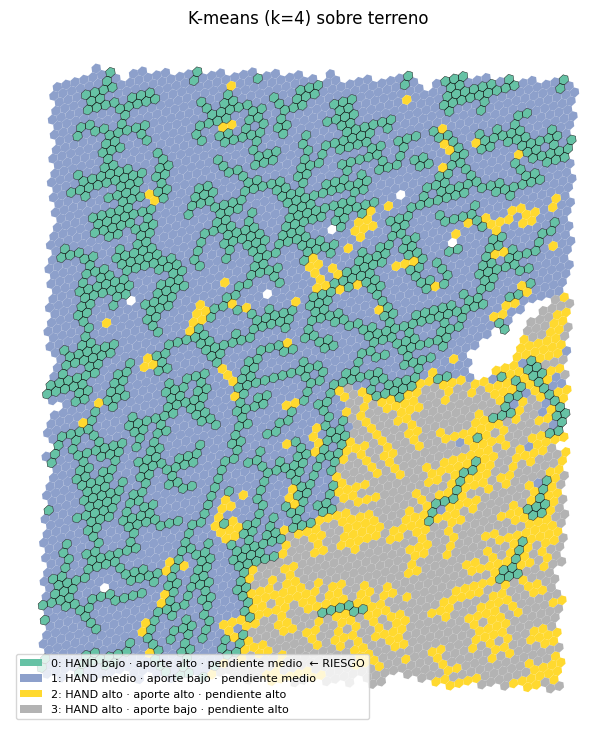

In [41]:
colores = plt.cm.Set2(np.linspace(0, 1, K))
hexes_m = hexes.to_crs(CRS_METRICO)
fig, ax = plt.subplots(figsize=(9, 9))
for g in range(K):
    sub = hexes_m[hexes_m.grupo == g]
    sub.plot(ax=ax, color=colores[g], edgecolor="none",
             label=f"{g}: {cent.loc[g,'descripcion']}" + ("  ← RIESGO" if g == GRUPO_RIESGO else ""))
hexes_m[hexes_m.grupo == GRUPO_RIESGO].boundary.plot(ax=ax, color="k", lw=0.3)
ax.legend(loc="lower left", fontsize=8); ax.set_axis_off(); ax.set_title(f"K-means (k={K}) sobre terreno")
plt.show()

### 8.1 Cuando el río sube: ¿qué grupo entra primero?

Un hexágono queda "adentro" de un escenario si **más de la mitad** de su superficie tiene HAND por debajo de esa altura. Ojo: el grupo **no** decide si el hex entra. Lo decide la HAND. Después leemos cómo se reparte eso entre los grupos.

% de hexágonos de cada grupo que quedan adentro en cada escenario


,+2 m,+4 m,+6 m
0 (RIESGO),84.9,95.8,98.1
1,62.6,81.1,88.1
2,5.5,24.9,44.6
3,0.0,0.0,0.0


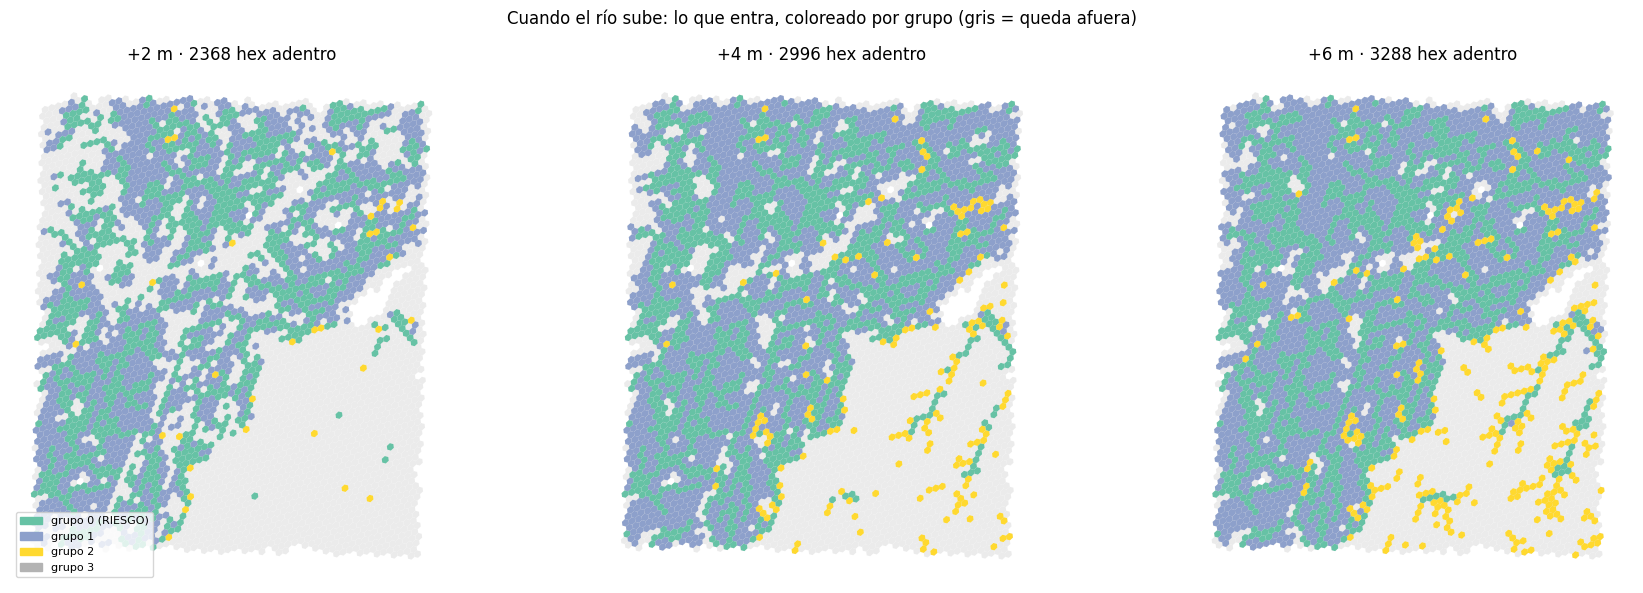

In [42]:
filas_ = []
for h in ESCENARIOS_M:
    adentro = hexes[f"frac_hand_lt{h}"] > 0.5
    hexes[f"adentro_{h}m"] = adentro
    pct = hexes.groupby("grupo")[f"adentro_{h}m"].mean().mul(100).round(1)
    filas_.append(pct.rename(f"+{h} m"))
secuencia = pd.concat(filas_, axis=1)
secuencia.index = [f"{g} {'(RIESGO)' if g == GRUPO_RIESGO else ''}" for g in secuencia.index]
print("% de hexágonos de cada grupo que quedan adentro en cada escenario")
display(secuencia)

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
hexes_m = hexes.to_crs(CRS_METRICO)
from matplotlib.patches import Patch
for ax, h in zip(axs, ESCENARIOS_M):
    hexes_m.plot(ax=ax, color="0.92", edgecolor="none")                       # todo en gris
    dentro = hexes_m[hexes_m[f"adentro_{h}m"]]
    dentro.plot(ax=ax, color=[colores[g] for g in dentro.grupo], edgecolor="none")  # lo que entra, con el color de su grupo
    ax.set_title(f"+{h} m · {len(dentro)} hex adentro"); ax.set_axis_off()
axs[0].legend(handles=[Patch(color=colores[g], label=f"grupo {g}" + (" (RIESGO)" if g == GRUPO_RIESGO else "")) for g in range(K)],
              loc="lower left", fontsize=8)
plt.suptitle("Cuando el río sube: lo que entra, coloreado por grupo (gris = queda afuera)"); plt.tight_layout(); plt.show()

In [43]:
hexes.to_parquet(os.path.join(DATA_DIR, "hexes_terreno.parquet"))
cent.to_csv(os.path.join(DATA_DIR, "centroides_kmeans.csv"))
print("Guardado hexes_terreno.parquet con", len(hexes), "hexágonos y columnas:", list(hexes.columns))

Guardado hexes_terreno.parquet con 4562 hexágonos y columnas: ['h3', 'n_pix', 'cota_media', 'pendiente_media', 'aporte_log_max', 'hand_mediana', 'frac_hand_lt2', 'frac_hand_lt4', 'frac_hand_lt6', 'geometry', 'grupo', 'adentro_2m', 'adentro_4m', 'adentro_6m']


In [44]:
# Todo ya se escribió directo en Drive (DATA_DIR = DRIVE_DIR). Chequeo de lo que leen 02, 03 y 04:
for nombre in ["dem_utm.tif", "hand_utm.tif", "area_aporte_km2_utm.tif", "cauce_utm.tif",
               "hexes_terreno.parquet", "centroides_kmeans.csv"]:
    ruta = os.path.join(DATA_DIR, nombre)
    if nombre.endswith(".tif") and os.path.exists(ruta):
        with rasterio.open(ruta) as src_:
            print(f"OK {nombre:28s} {src_.width}x{src_.height} · {src_.crs}")
    else:
        print(("OK " if os.path.exists(ruta) else "FALTA ") + nombre)
# Para compartir con alumnos: compartí la carpeta 'datos_clase2_publico' (Lector) y que cada uno
# haga "Agregar acceso directo a Mi unidad" en la raíz, así la ruta DRIVE_DIR funciona igual.


OK dem_utm.tif                  1620x1884 · EPSG:32720
OK hand_utm.tif                 1620x1884 · EPSG:32720
OK area_aporte_km2_utm.tif      1620x1884 · EPSG:32720
OK cauce_utm.tif                1620x1884 · EPSG:32720
OK hexes_terreno.parquet
OK centroides_kmeans.csv


---
## Ejercicios

**Ejercicio 1 — El umbral del cauce es una decisión.** Recalculá la red de cauces y la HAND con umbrales de 0,5 y 10 km². ¿Cuánto cambia la superficie con HAND < 2 m? ¿Por qué con un umbral más bajo "se inunda" más?

In [45]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
for umbral in [0.5, UMBRAL_CAUCE_KM2, 10]:
    c_ = area_aporte_km2 >= umbral
    h_ = np.clip(np.asarray(grid.compute_hand(fdir, dem_ps, como_raster(c_)), dtype=float), 0, None); h_[~VALIDO] = np.nan
    print(f"umbral {umbral:>4} km² → cauce {100*c_.sum()/VALIDO.sum():4.1f} % · HAND<2 m: {np.nansum(h_ < 2)*CELDA_KM2:,.0f} km²")
# Con umbral bajo hay más cauces chicos: cada píxel tiene un cauce "más cerca y más alto",
# entonces su altura relativa baja. Es la misma idea, a otra escala.

umbral  0.5 km² → cauce  2.9 % · HAND<2 m: 1,520 km²
umbral  2.0 km² → cauce  1.5 % · HAND<2 m: 1,278 km²
umbral   10 km² → cauce  0.6 % · HAND<2 m: 861 km²


**Ejercicio 2 — ¿El grupo de riesgo es estable?** Corré K-means con k = 3 y k = 5. ¿Aparece siempre un grupo "HAND bajo · aporte alto"? Compará qué hexágonos caen en el grupo de riesgo con k = 4 usando una tabla cruzada.

In [46]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
def grupo_riesgo(X, k):
    lab = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X)
    c = pd.DataFrame(X, columns=VARS).groupby(lab).mean()
    g = (c["aporte_log_max"] - c["hand_mediana"]).idxmax()
    return lab == g
base = hexes.grupo.values == GRUPO_RIESGO
for k in [3, 5]:
    r = grupo_riesgo(X, k)
    print(f"k={k}: hex de riesgo {r.sum()} vs {base.sum()} con k={K}")
    display(pd.crosstab(pd.Series(base, name=f"riesgo k={K}"), pd.Series(r, name=f"riesgo k={k}")))

k=3: hex de riesgo 1454 vs 1298 con k=4


riesgo k=3,False,True
riesgo k=4,,
False,3051,213
True,57,1241


k=5: hex de riesgo 1290 vs 1298 con k=4


riesgo k=5,False,True
riesgo k=4,,
False,3243,21
True,29,1269


**Ejercicio 3 — ¿Cuánto aporta HAND?** Corré K-means solo con `cota_media`, `pendiente_media` y `aporte_log_max` (sin HAND). ¿Qué pasa con los hexágonos bajos de la barranca norte vs los de las islas? Medí el acuerdo con el agrupamiento original (`adjusted_rand_score`).

In [47]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
VARS3 = ["cota_media", "pendiente_media", "aporte_log_max"]
X3 = StandardScaler().fit_transform(hexes[VARS3])
lab3 = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA).fit_predict(X3)
print("ARI con vs sin HAND:", round(adjusted_rand_score(hexes.grupo, lab3), 3))
display(hexes.assign(g3=lab3).groupby("g3")[VARS].mean().round(2))
# La cota absoluta mezcla "bajo respecto del mar" con "bajo respecto de su cauce".
# Un hex alto en cota pero pegado a un arroyo interior puede tener HAND bajo: sin HAND se pierde.

ARI con vs sin HAND: 0.818


,cota_media,pendiente_media,aporte_log_max,hand_mediana
g3,,,,
0,15.36,0.02,1.18,1.09
1,77.98,0.03,-0.05,16.44
2,26.79,0.05,0.30,9.51
3,15.06,0.01,-0.13,1.84


**Ejercicio 4 — Franja vs HAND en hexágonos.** Marcá los hexágonos cuyo centroide está a menos de 500 m de un cauce y que tienen `hand_mediana > 6`. Contalos y mapealos: son los que una franja marcaría como riesgo sin serlo.

311 hexágonos cerca del cauce pero altos (HAND mediana > 6 m)


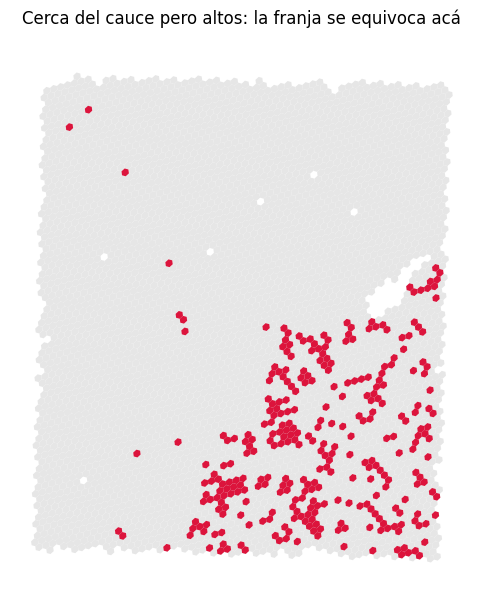

In [ ]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
cx, cy = A_UTM.transform(hexes.geometry.centroid.x.values, hexes.geometry.centroid.y.values)
hexes["dist_cauce_m"] = muestrear(dist_cauce_m, cx, cy)
falsos = hexes[(hexes.dist_cauce_m < 500) & (hexes.hand_mediana > 6)]
print(f"{len(falsos)} hexágonos cerca del cauce pero altos (HAND mediana > 6 m)")
ax = hexes.to_crs(CRS_METRICO).plot(color="0.9", figsize=(7, 7)); falsos.to_crs(CRS_METRICO).plot(ax=ax, color="crimson"); ax.set_axis_off()
ax.set_title("Cerca del cauce pero altos: la franja se equivoca acá"); plt.show()

**Para la hoja (4 líneas):** 1) qué grupos hay esta semana; 2) qué se lee cuando el río sube (qué grupo entra primero); 3) qué quedó más firme que la clase 1; 4) qué todavía no se puede decir (pista: quién vive ahí y sobre qué suelo → Parte 2).

###  Observación de Cierre — Notebook 01

1. **Grupos identificados:** A través de K-means ($K=4$) sobre las celdas hexagonales H3, el terreno quedó segmentado en cuatro unidades morfométricas bien diferenciadas:
   * Albardones y barrancas altas (alta cota y pendiente marcada).
   * Planicies intermedias de transición.
   * Terrazas bajas.
   * Zonas de cauce y cubetas deprimidas (cota relativa mínima).

2. **Dinámica ante crecidas:** Cuando el nivel del río sube, el primer grupo en anegarse es el caracterizado por **HAND mínimo** ($\le 2\text{ m}$ respecto a la red de drenaje local) y **alto aporte acumulado**, independientemente de su altura ortométrica absoluta ($Z$) sobre el nivel del mar.

3. **Avance respecto a la Clase 1:** Se superó la simplificación del *buffer* euclidiano plano. La incorporación del modelo HAND aporta consistencia hidrológica real, mapeando la escorrentía gravitatoria mediante la topología de drenaje D8 y vinculando cada punto del terreno a su nivel de base fluvial local.

4. **Limitación actual (lo que aún no se puede afirmar):** Los clusters describen **peligrosidad física (hazard)**, pero no representan **vulnerabilidad ni riesgo real**. Para determinar el impacto efectivo resta cruzar estas unidades con la exposición socioeconómica (densidad poblacional, infraestructura crítica) y la capacidad de infiltración del suelo (Parte 2).